In [27]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, CSVLogger
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [30]:
import os

# 1. Vérifier dans le sous-dossier du dataset
sub_path = "/content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset"
if os.path.exists(sub_path):
    print(f"Contenu de '{sub_path}' :")
    for element in sorted(os.listdir(sub_path)):
        print(f" - {element}")
else:
    print(f"Le sous-dossier '{sub_path}' n'existe pas.")

print("\n" + "="*50 + "\n")

# 2. Chercher globalement tous les fichiers .csv dans le dossier du projet pour les localiser rapidement
print("Recherche de tous les fichiers .csv présents dans le dossier du projet :")
found_csvs = []
for root, dirs, files in os.walk("/content/drive/MyDrive/projet covid radiographie pulmonaire"):
    for file in files:
        if file.endswith('.csv'):
            found_csvs.append(os.path.join(root, file))

if found_csvs:
    for csv_path in found_csvs:
        print(f" - Trouvé : {csv_path}")
else:
    print("Aucun fichier CSV n'a été trouvé dans l'arborescence du projet.")

Contenu de '/content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset' :
 - COVID
 - COVID.metadata.xlsx
 - Lung_Opacity
 - Lung_Opacity.metadata.xlsx
 - Normal
 - Normal.metadata.xlsx
 - README.md.txt
 - Viral Pneumonia
 - Viral Pneumonia.metadata.xlsx
 - test (1) (1).csv
 - train (1).csv
 - validation (1).csv


Recherche de tous les fichiers .csv présents dans le dossier du projet :
 - Trouvé : /content/drive/MyDrive/projet covid radiographie pulmonaire/dataset_summary.csv
 - Trouvé : /content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset/test (1) (1).csv
 - Trouvé : /content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset/train (1).csv
 - Trouvé : /content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset/validation (1).csv


In [ ]:
PROJECT_DIR = Path("/content/drive/MyDrive/projet covid radiographie pulmonaire")
DATA_DIR = PROJECT_DIR / "COVID-19_Radiography_Dataset"
DATASET_ROOT = PROJECT_DIR / "COVID-19_Radiography_Dataset"
if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(f"Dossier projet introuvable : {PROJECT_DIR}. Monter Drive et vérifier PROJECT_DIR.")
if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(f"Dossier images introuvable : {DATASET_ROOT}. Respecter l'arborescence Kaggle.")
OUTPUT_DIR = Path(".")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ["COVID", "Normal", "Lung_Opacity", "Viral Pneumonia"]
EXPECTED = {"train": 13545, "validation": 3387, "test": 4233}
BATCH_SIZE = 32
IMG_HEIGHT, IMG_WIDTH = 224, 224
SEED = 42
tf.keras.utils.set_random_seed(SEED)

train_df = pd.read_csv(DATA_DIR / "train (1).csv")
val_df = pd.read_csv(DATA_DIR / "validation (1).csv")
test_df = pd.read_csv(DATA_DIR / "test (1) (1).csv")

# CONFLIT — AJOUT : contrôle du split commun et des étiquettes multiclasse.
for name, frame in (("train", train_df), ("validation", val_df), ("test", test_df)):
    assert {"filepath", "target", "class"}.issubset(frame.columns), f"{name}: colonnes manquantes"
    assert len(frame) == EXPECTED[name], f"{name}: {len(frame)} au lieu de {EXPECTED[name]}"
    assert frame[["filepath", "target", "class"]].notna().all().all(), f"{name}: valeurs nulles"
    assert frame["filepath"].is_unique, f"{name}: images dupliquées"
    assert set(frame["class"].unique()) <= set(CLASSES), f"{name}: classes inconnues"
    assert set(frame["target"].astype(str).unique()) <= {"0", "1"}
    assert (frame["target"].astype(str).eq("1") == frame["class"].eq("COVID")).all(), f"{name}: target / class incohérents"
    print(f"{name}: {len(frame)} images ; classes = {frame['class'].value_counts().to_dict()}")
assert set(train_df["class"]) == set(CLASSES)
assert set(val_df["class"]) == set(CLASSES)
train_paths = set(train_df["filepath"].astype(str))
val_paths = set(val_df["filepath"].astype(str))
test_paths = set(test_df["filepath"].astype(str))
assert not (train_paths & val_paths or train_paths & test_paths or val_paths & test_paths), "Fuite entre splits"


train_gen_df = train_df.copy()
val_gen_df = val_df.copy()
test_gen_df = test_df.copy()


def resolve_image_path(csv_path):
    normalized = str(csv_path).replace("\\", "/")
    marker = "COVID-19_Radiography_Dataset/"
    if marker not in normalized:
        raise ValueError(f"Chemin CSV sans dossier dataset : {csv_path}")
    relative = normalized.split(marker, 1)[1]
    parts = Path(relative).parts
    if len(parts) != 3 or parts[1] != "images" or parts[0] not in CLASSES:
        raise ValueError(f"Structure d'image inattendue : {csv_path}")
    return str(DATASET_ROOT.joinpath(*parts))

train_gen_df["filepath"] = train_gen_df["filepath"].map(resolve_image_path)
val_gen_df["filepath"] = val_gen_df["filepath"].map(resolve_image_path)
test_gen_df["filepath"] = test_gen_df["filepath"].map(resolve_image_path)

# CONFLIT — AJOUT : vérification avant le fit, y compris pour le test non exploité.
for name, frame in (("train", train_gen_df), ("validation", val_gen_df), ("test", test_gen_df)):
    missing = [p for p in frame["filepath"] if not Path(p).is_file()]
    if missing:
        raise FileNotFoundError(f"{name}: {len(missing)} fichiers absents. Exemple : {missing[0]}. Vérifier PROJECT_DIR.")
    print(f"{name}: {len(frame)} chemins existants")

# CONFLIT — MODIFICATION : variante E2 = DA seule ; aucun oversampling.
train_fit_df = train_gen_df.copy()
assert len(train_fit_df) == EXPECTED["train"]
print("Train sans OS :", train_fit_df["class"].value_counts().to_dict())

train: 13545 images ; classes = {'Normal': 6495, 'Lung_Opacity': 3895, 'COVID': 2314, 'Viral Pneumonia': 841}
validation: 3387 images ; classes = {'Normal': 1607, 'Lung_Opacity': 977, 'COVID': 579, 'Viral Pneumonia': 224}
test: 4233 images ; classes = {'Normal': 2090, 'Lung_Opacity': 1140, 'COVID': 723, 'Viral Pneumonia': 280}
train: 13545 chemins existants
validation: 3387 chemins existants
test: 4233 chemins existants
Train sans OS : {'Normal': 6495, 'Lung_Opacity': 3895, 'COVID': 2314, 'Viral Pneumonia': 841}


In [ ]:

train_fit_df = train_gen_df.copy()
assert len(train_fit_df) == EXPECTED["train"]
print("Train sans OS :", train_fit_df["class"].value_counts().to_dict())

Train sans OS : {'Normal': 6495, 'Lung_Opacity': 3895, 'COVID': 2314, 'Viral Pneumonia': 841}


In [39]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=False
)
val_datagen = ImageDataGenerator(rescale=1./255)

# CONFLIT — MODIFICATION : 4 classes (colonne class) au lieu du target binaire.
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_fit_df, x_col="filepath", y_col="class",
    target_size=(IMG_HEIGHT, IMG_WIDTH), color_mode="grayscale",
    classes=CLASSES, class_mode="categorical", batch_size=BATCH_SIZE,
    shuffle=True, seed=SEED
)
val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_gen_df, x_col="filepath", y_col="class",
    target_size=(IMG_HEIGHT, IMG_WIDTH), color_mode="grayscale",
    classes=CLASSES, class_mode="categorical", batch_size=BATCH_SIZE,
    shuffle=False
)
assert train_generator.n == len(train_fit_df), "Train : images écartées par le générateur"
assert val_generator.n == EXPECTED["validation"], "Validation : images écartées"
assert val_generator.class_indices == {name: i for i, name in enumerate(CLASSES)}
assert val_generator.shuffle is False
print("Train batches:", len(train_generator), "Val batches:", len(val_generator))
print("Index des classes:", val_generator.class_indices)

Found 13545 validated image filenames belonging to 4 classes.
Found 3387 validated image filenames belonging to 4 classes.
Train batches: 424 Val batches: 106
Index des classes: {'COVID': 0, 'Normal': 1, 'Lung_Opacity': 2, 'Viral Pneumonia': 3}


In [40]:
def build_cnn_multiclass():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 1)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(4, activation="softmax")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

model = build_cnn_multiclass()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,168,900 (42.61 MB)

 Trainable params: 11,168,900 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

MODEL_PATH = OUTPUT_DIR / "M_CNN_from_E2_multiclass_best.keras"
HISTORY_PATH = OUTPUT_DIR / "M_CNN_from_E2_multiclass_history.csv"
callbacks = [
    EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    ModelCheckpoint(str(MODEL_PATH), monitor="val_loss", save_best_only=True),
    CSVLogger(str(HISTORY_PATH))
]
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5,
    callbacks=callbacks
)
print("Meilleur checkpoint :", MODEL_PATH)

Epoch 1/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 1773s 4s/step - accuracy: 0.5971 - loss: 0.9410 - val_accuracy: 0.6864 - val_loss: 0.7236
Epoch 2/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 1565s 4s/step - accuracy: 0.6829 - loss: 0.7692 - val_accuracy: 0.7535 - val_loss: 0.6343
Epoch 3/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 1559s 4s/step - accuracy: 0.7254 - loss: 0.6860 - val_accuracy: 0.7927 - val_loss: 0.5351
Epoch 4/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 1580s 4s/step - accuracy: 0.7440 - loss: 0.6503 - val_accuracy: 0.8066 - val_loss: 0.5064
Epoch 5/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 1599s 4s/step - accuracy: 0.7680 - loss: 0.6044 - val_accuracy: 0.8143 - val_loss: 0.4888
Meilleur checkpoint : M_CNN_from_E2_multiclass_best.keras


106/106 ━━━━━━━━━━━━━━━━━━━━ 103s 963ms/step
                 precision    recall  f1-score     support
COVID             0.774351  0.823834  0.798326   579.00000
Normal            0.803005  0.897946  0.847826  1607.00000
Lung_Opacity      0.840244  0.705220  0.766834   977.00000
Viral Pneumonia   0.967532  0.665179  0.788360   224.00000
accuracy          0.814290  0.814290  0.814290     0.81429
macro avg         0.846283  0.773045  0.800336  3387.00000
weighted avg      0.819729  0.814290  0.812069  3387.00000
Accuracy : 0.8142899320932979
F1 macro : 0.8003364616809483
Recall macro : 0.7730448284660434
Recall COVID : 0.8238341968911918
F1 COVID : 0.798326359832636


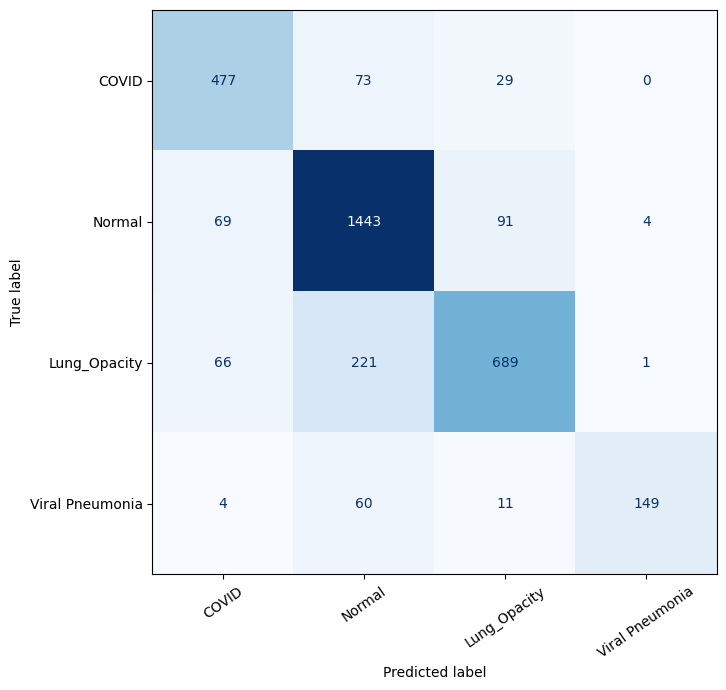

In [42]:
best_model = tf.keras.models.load_model(str(MODEL_PATH))
val_generator.reset()
proba = best_model.predict(val_generator, verbose=1)
assert len(proba) == val_generator.n == EXPECTED["validation"]
y_pred = np.argmax(proba, axis=1)
y_true = val_generator.classes
labels = list(range(len(CLASSES)))
report = classification_report(
    y_true, y_pred, labels=labels, target_names=CLASSES,
    output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv(OUTPUT_DIR / "M_CNN_from_E2_classification_report.csv")
print(report_df.to_string())
print("Accuracy :", report["accuracy"])
print("F1 macro :", report["macro avg"]["f1-score"])
print("Recall macro :", report["macro avg"]["recall"])
print("Recall COVID :", report["COVID"]["recall"])
print("F1 COVID :", report["COVID"]["f1-score"])

cm = confusion_matrix(y_true, y_pred, labels=labels)
pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(
    OUTPUT_DIR / "M_CNN_from_E2_confusion_matrix.csv"
)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES).plot(
    ax=ax, cmap="Blues", xticks_rotation=35, colorbar=False
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "M_CNN_from_E2_confusion_matrix.png", dpi=160)
plt.show()

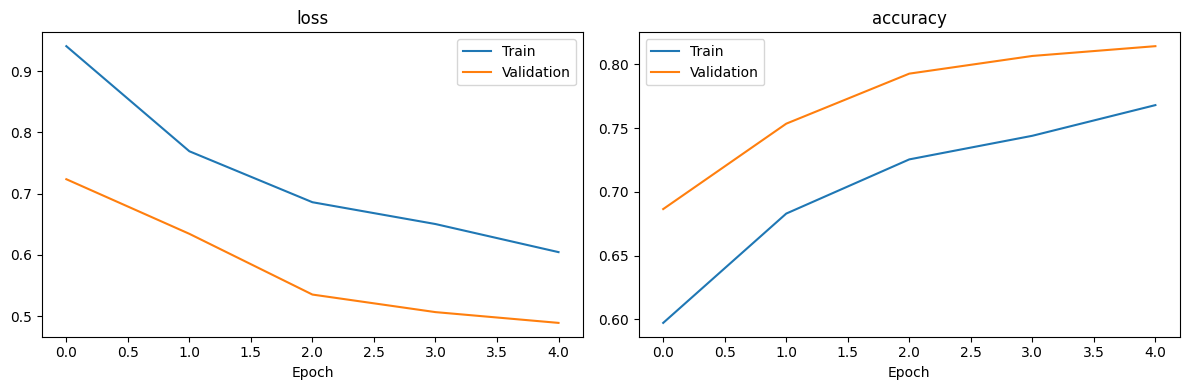

In [43]:
history_df = pd.read_csv(HISTORY_PATH)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(history_df[metric], label="Train")
    ax.plot(history_df["val_" + metric], label="Validation")
    ax.set_title(metric)
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "M_CNN_from_E2_learning_curves.png", dpi=160)
plt.show()
